# Simulation and Modeling of Vegetable Market Price Fluctuation

**Course:** Simulation and Modeling Lab (`CSE 413`) — Level 4, Term 1  
**Course Teacher:** Audity Ghosh, Lecturer, Department of CSE, University of Information Technology and Sciences (UITS)  
**Submitted by:** Elham Rafat Mahmud(1056) Fahim Hossain (1085)

## 1. Introduction & Variable Taxonomy

Vegetable prices in Bangladeshi retail markets do not stay still. A kilogram of tomato can cost far less in winter than in the monsoon, and a flood, transport strike, or supply disruption can push prices up overnight. Because we cannot run controlled experiments on real agricultural markets, **stochastic simulation** lets us build a synthetic market with known rules, generate years of daily prices, and test statistical methods under controlled conditions.

### 1.1 Statistical Variable Taxonomy
Before building the simulation, we classify each variable in the model so that every statistical test matches its measurement scale:

| Variable | Broad Category | Sub-Type & Scale | Role in Simulation & Statistical Testing |
| :--- | :--- | :--- | :--- |
| `Vegetable` (`Tomato`, `Potato`, `Onion`, `Brinjal`) | **Qualitative (Categorical)** | **Nominal** (Unordered categories) | Identifies each crop's base price $B_v$, seasonal amplitude $A_v$, peak day, daily noise $\sigma_v$, and shock sensitivity $k_v$ |
| `Season` (`Winter`, `Summer`, `Monsoon`, `Autumn`) | **Qualitative (Categorical)** | **Nominal** (Cyclic calendar categories with no natural rank order) | Grouping variable for seasonal comparisons (Two-Sample *t*-test and Chi-Square Goodness-of-Fit) |
| `DayOfYear` ($d_t \in \{1,\dots,365\}$) | **Quantitative (Numerical)** | **Discrete / Interval** (Circular calendar position) | Drives deterministic seasonal wave $S_{v,t}$ and 3D cylindrical phase angle $\theta_t = 2\pi d_t / 365$ |
| `ShockStart` ($0/1$ indicator, seasonal count $O_i$) | **Quantitative (Numerical)** | **Discrete / Ratio** (Event count) | Observed shock-arrival frequency $O_i$ in the Chi-Square Goodness-of-Fit test |
| `Price` ($P_{v,t}$ in Tk/kg) & `Basket Cost` (Tk/month) | **Quantitative (Numerical)** | **Continuous / Ratio** (Positive real values) | Primary response variable for descriptive statistics, *t*-tests, and Monte Carlo budget risk |
| `LogReturn` ($r_{v,t} = \ln(P_{v,t}/P_{v,t-1})$) | **Quantitative (Numerical)** | **Continuous / Ratio** (Daily percentage change) | Isolates day-to-day co-movement across crops for correlation and eigenvalue factor analysis |

## 2. Necessary Libraries

In [24]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

# Configure plotting style and pandas numerical output format
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)
print("Libraries loaded successfully. You can now execute the subsequent simulation steps.")

Libraries loaded successfully. You can now execute the subsequent simulation steps.


## 4. The Simulation Model

The daily retail price of vegetable $v$ on day $t$ is built from **four multiplicative parts** so that swings scale naturally as percentages and prices can never turn negative:

$$P_{v,t} = B_v \times S_{v,t} \times e^{X_{v,t}} \times \left(1 + k_v \, Z_t\right)$$

| Part | Meaning | How it is generated |
| :--- | :--- | :--- |
| $B_v$ | Base price (Tk/kg) | Fixed baseline assumption per vegetable (`60`, `35`, `70`, `55` Tk/kg) |
| $S_{v,t}$ | Seasonal factor | $1 + A_v \sin\!\left(\frac{2\pi (d_t - \text{peak}_v + 91.25)}{365}\right)$, peaking on day $d_t = \text{peak}_v$ |
| $X_{v,t}$ | Persistent daily market noise | $X_{v,t} = 0.90\,X_{v,t-1} + \varepsilon_{v,t}$ with $\varepsilon_{v,t} \sim \mathcal{N}(0, \sigma_v^2)$ so daily moves persist across days |
| $Z_t$ | Market-wide supply shock | Starts when `np.random.rand() < p_t` ($p_t = 0.06$ in Monsoon Jun–Sep, $0.02$ otherwise) with jump $\text{Uniform}(0.15, 0.50)$ and decays via $Z_t = 0.85\,Z_{t-1} + \text{new\_shock}_t$ |
| $k_v$ | Shock sensitivity | Perishable Tomato ($k=1.0$) reacts strongly; cold-stored Potato ($k=0.4$) reacts weakly |

In [25]:
# ---------- Model parameters (all assumptions, easy to change) ----------
VEG = {
    # Each crop contains: base price (Tk/kg), seasonal amplitude (as a fraction of base),
    # peak day of year (1-365), daily noise standard deviation (sigma), and sensitivity to market shocks.
    "Tomato":  dict(base=60, amp=0.25, peak=220, sigma=0.030, sens=1.0),
    "Potato":  dict(base=35, amp=0.10, peak=240, sigma=0.012, sens=0.4),
    "Onion":   dict(base=70, amp=0.15, peak=280, sigma=0.025, sens=0.8),
    "Brinjal": dict(base=55, amp=0.12, peak=200, sigma=0.025, sens=0.7),
}
PHI   = 0.90    # Autoregressive AR(1) parameter: day-to-day persistence of market noise
DECAY = 0.85    # Decay factor for market-wide shocks (how fast the shock fades out each day)
P_MONSOON, P_OTHER = 0.06, 0.02   # Daily probability of a new market shock starting in Monsoon vs. other seasons

def seasons_of(dates):
    """Assigns a season name to each calendar date based on standard Bangladeshi seasonal months."""
    m = dates.month
    return np.select([m.isin([12, 1, 2]), m.isin([3, 4, 5]), m.isin([6, 7, 8, 9])],
                     ["Winter", "Summer", "Monsoon"], "Autumn")

def simulate(n_runs, dates):
    """Simulate n_runs independent price histories over the given dates.
    Returns (prices dict of arrays [n_runs x n_days], shock-start boolean array, Z array)."""
    n = len(dates)
    doy = dates.dayofyear.values
    monsoon = np.isin(dates.month, [6, 7, 8, 9])
    # Assign daily shock probabilities based on season
    p = np.where(monsoon, P_MONSOON, P_OTHER)

    # Uniform random numbers decide if a shock starts; Uniform sizes set its strength
    event = np.random.rand(n_runs, n) < p
    size = np.random.uniform(0.15, 0.50, (n_runs, n))
    new_shock = np.where(event, size, 0.0)

    # Iterate through days to accumulate and decay the shocks (AR(1) shock process)
    Z = np.zeros((n_runs, n))
    for t in range(n):
        Z[:, t] = DECAY * (Z[:, t-1] if t > 0 else 0) + new_shock[:, t]

    prices = {}
    for name, v in VEG.items():
        # Generate independent daily noise epsilon ~ N(0, sigma^2)
        eps = np.random.normal(0, v["sigma"], (n_runs, n))
        X = np.zeros((n_runs, n))
        # Generate persistent noise X_t = PHI * X_{t-1} + eps_t
        for t in range(n):
            X[:, t] = PHI * (X[:, t-1] if t > 0 else 0) + eps[:, t]
        # Calculate deterministic sinusiodal seasonal factor
        seasonal = 1 + v["amp"] * np.sin(2 * np.pi * (doy - v["peak"] + 91.25) / 365)
        # Compose final multiplicative price: P = Base * Seasonal * exp(Noise) * (1 + Sensitivity * Shock)
        prices[name] = v["base"] * seasonal * np.exp(X) * (1 + v["sens"] * Z)
    return prices, event, Z

pd.DataFrame(VEG).T

,base,amp,peak,sigma,sens
Tomato,60.0,0.25,220.0,0.03,1.0
Potato,35.0,0.10,240.0,0.01,0.4
Onion,70.0,0.15,280.0,0.03,0.8
Brinjal,55.0,0.12,200.0,0.03,0.7


## 5. Running the Simulation: 5 Years of Daily Prices (`1,825` Days)

We fix `np.random.seed(42)` and simulate 5 years (`1,825` days from `2021-01-01` to `2025-12-30`). Simulating 5 years gives enough independent supply-shock events (`54` shocks for `seed=42`) so that every season has an expected count well above `5` in the Chi-Square test.

In [26]:
# Set random seed for reproducibility
np.random.seed(42)
dates = pd.date_range("2021-01-01", periods=5 * 365)

# Run the simulation for 1 history spanning 5 years
prices, event, Z_series = simulate(1, dates)

# Construct a DataFrame with the output arrays
df = pd.DataFrame({name: arr[0] for name, arr in prices.items()}, index=dates)
df["ShockStart"] = event[0]
df["ShockLevel"] = Z_series[0]
df["Season"] = seasons_of(dates)

print(f"Total simulated days: {len(df)} | Total supply-shock starts: {int(df['ShockStart'].sum())}")
df.head(8)

Total simulated days: 1825 | Total supply-shock starts: 54


,Tomato,Potato,Onion,Brinjal,ShockStart,ShockLevel,Season
2021-01-01,47.12,33.26,69.28,48.98,False,0.0,Winter
2021-01-02,49.04,33.35,70.49,47.32,False,0.0,Winter
2021-01-03,48.20,33.41,69.43,46.91,False,0.0,Winter
2021-01-04,48.54,33.35,67.62,48.09,False,0.0,Winter
2021-01-05,48.49,33.24,68.19,48.54,False,0.0,Winter
2021-01-06,45.25,34.11,63.80,49.21,False,0.0,Winter
2021-01-07,46.36,34.41,61.48,49.60,False,0.0,Winter
2021-01-08,46.60,34.49,61.84,51.52,False,0.0,Winter


### 5.1 Descriptive statistics (Tk/kg)
The **coefficient of variation (`CV % = std / mean * 100`)** puts volatility on a common percentage scale across crops with different baseline prices.

In [27]:
veg_cols = list(VEG.keys())
summary = df[veg_cols].agg(["mean", "std", "min", "max"]).T
summary["CV (%)"] = summary["std"] / summary["mean"] * 100
summary.round(2)

,mean,std,min,max,CV (%)
Tomato,63.30,14.52,39.15,126.61,22.94
Potato,35.76,3.50,29.02,48.82,9.79
Onion,73.47,10.78,51.44,128.05,14.67
Brinjal,57.38,7.63,43.41,89.55,13.29


### 5.2 Daily price trajectories (`2021–2025`)

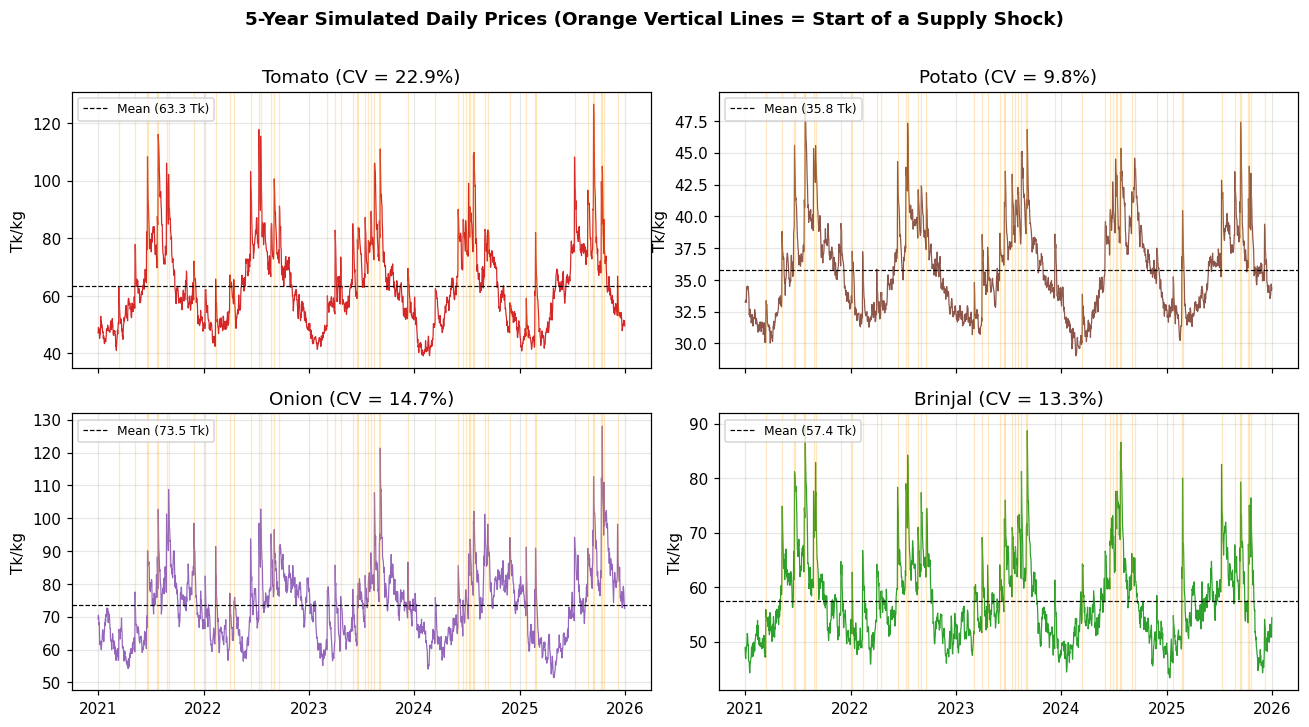

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
colors = ["tab:red", "tab:brown", "tab:purple", "tab:green"]
shock_days = df.index[df["ShockStart"]]

for ax, name, col in zip(axes.ravel(), veg_cols, colors):
    ax.plot(df.index, df[name], color=col, linewidth=0.8)
    ax.axhline(df[name].mean(), color="black", linestyle="--", linewidth=0.8, label=f"Mean ({df[name].mean():.1f} Tk)")
    for d in shock_days:
        ax.axvline(d, color="orange", alpha=0.25, linewidth=0.8)
    ax.set_title(f"{name} (CV = {summary.loc[name, 'CV (%)']:.1f}%)")
    ax.set_ylabel("Tk/kg"); ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("5-Year Simulated Daily Prices (Orange Vertical Lines = Start of a Supply Shock)", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

### 5.3 Price distributions & 5.4 Seasonal pattern (average Tk/kg by season)

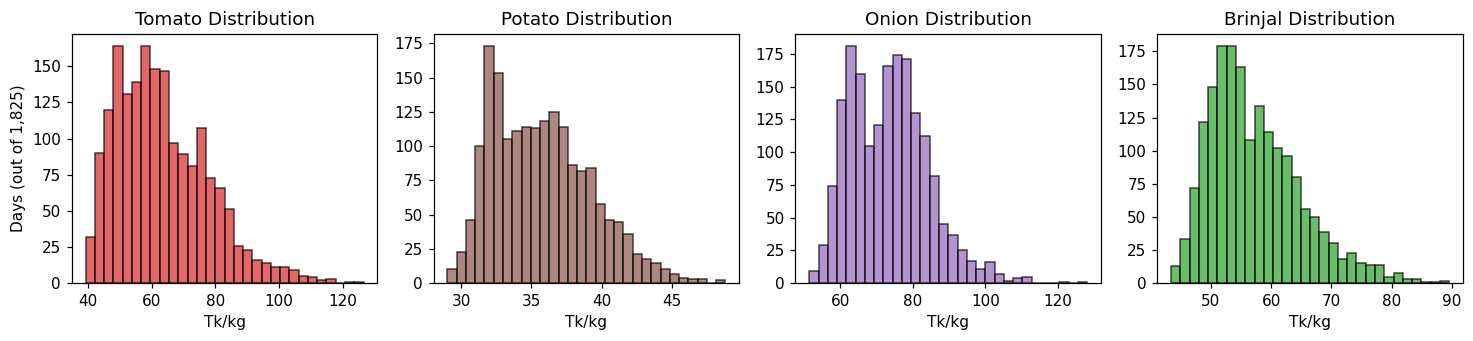

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.2))
for ax, name, col in zip(axes, veg_cols, colors):
    ax.hist(df[name], bins=30, color=col, alpha=0.7, edgecolor="black")
    ax.set_title(f"{name} Distribution"); ax.set_xlabel("Tk/kg")
axes[0].set_ylabel("Days (out of 1,825)")
plt.tight_layout(); plt.show()

,Tomato,Potato,Onion,Brinjal
Season,,,,
Winter,49.53,33.01,70.09,50.97
Summer,56.78,33.13,63.32,55.72
Monsoon,78.63,39.41,79.58,64.99
Autumn,62.78,36.46,81.55,54.14


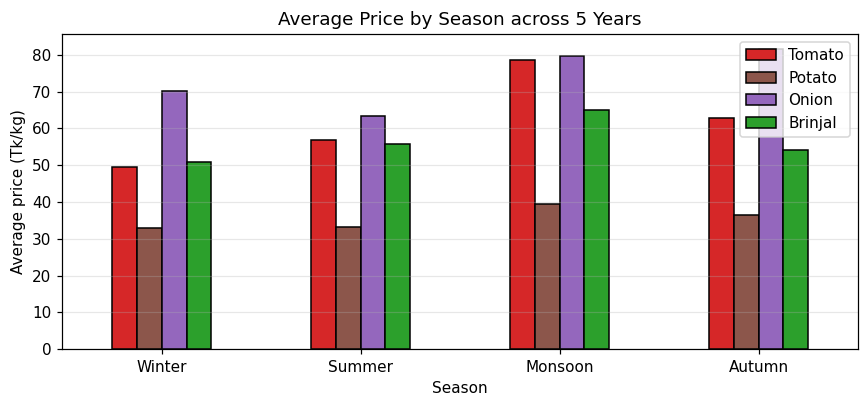

In [30]:
order = ["Winter", "Summer", "Monsoon", "Autumn"]
season_mean = df.groupby("Season")[veg_cols].mean().reindex(order)
display(season_mean.round(2))

ax = season_mean.plot(kind="bar", figsize=(8, 3.8), edgecolor="black", color=colors)
plt.ylabel("Average price (Tk/kg)"); plt.title("Average Price by Season across 5 Years")
plt.xticks(rotation=0); plt.grid(True, axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 6. Cross-Crop Co-Movement & Shared Factor Analysis

In our model, each vegetable has its own independent daily noise $\varepsilon_{v,t}$, but all four vegetables experience the **same market-wide supply shock $Z_t$** (scaled by sensitivity $k_v$). We use the matrix and eigenvalue tools from **Lab 1** and **Lab 2** to answer a concrete modeling question: *How much of the day-to-day movement across the four vegetables comes from one shared market factor?*

- **Why correlate daily log-returns instead of price levels?** Correlating raw price levels ($P_{v,t}$) mixes together deterministic seasonal cycles and multi-day shock persistence. Taking **daily log-returns** $r_{v,t} = \ln(P_{v,t} / P_{v,t-1})$ removes the slow seasonal level and isolates same-day jumps.
- **Why compute eigenvalues of the correlation matrix $R$ instead of the covariance matrix?** In a raw covariance matrix, Tomato's eigenvalue looks huge simply because Tomato has a larger variance in $\text{Tk}^2$. Using the **$4\times 4$ log-return correlation matrix $R$** standardizes all four vegetables to unit variance (so the `4` eigenvalues sum to exactly `4.0`), showing the true share of variance explained by the common shock factor.

Highest Seasonal Average : 81.55 Tk/kg -> (Autumn, Onion)
Lowest Seasonal Average  : 33.01 Tk/kg -> (Winter, Potato)

--- Daily Log-Return Correlation Matrix (R) ---


,Tomato,Potato,Onion,Brinjal
Tomato,1.00,0.72,0.68,0.68
Potato,0.72,1.00,0.70,0.69
Onion,0.68,0.70,1.00,0.67
Brinjal,0.68,0.69,0.67,1.00


Matrix shape: (4, 4) | Rank: 4 | Determinant det(R): 0.0923
Eigenvalues of R (sum = 4.0): [3.064 0.335 0.323 0.279]
Share of variance explained by each factor: [76.6  8.4  8.1  7. ]%
-> Dominant 1st eigenvalue explains 76.6% of daily return variance across all 4 crops (the shared shock Z_t).


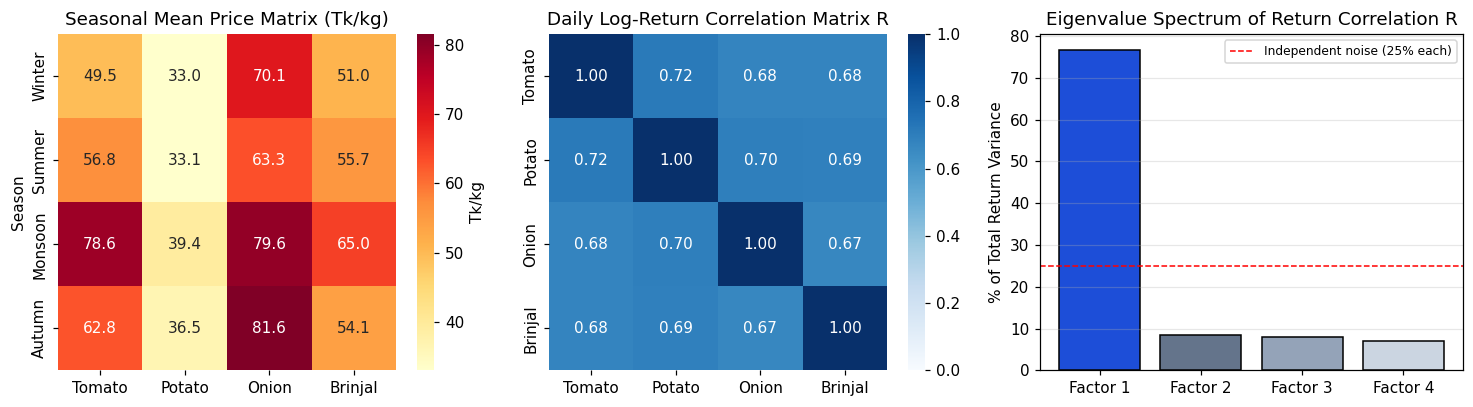

In [31]:
# 6.1  2D Index Unraveling on the 4x4 Seasonal Mean Matrix
season_mat = season_mean.values
# Find the coordinates (indices) of the absolute maximum and minimum seasonal values
max_r, max_c = np.unravel_index(np.argmax(season_mat), season_mat.shape)
min_r, min_c = np.unravel_index(np.argmin(season_mat), season_mat.shape)
print(f"Highest Seasonal Average : {season_mat[max_r, max_c]:.2f} Tk/kg -> ({order[max_r]}, {veg_cols[max_c]})")
print(f"Lowest Seasonal Average  : {season_mat[min_r, min_c]:.2f} Tk/kg -> ({order[min_r]}, {veg_cols[min_c]})")

# 6.2 Daily Log-Returns vs. Price Levels Correlation
# Take the natural log-return to neutralize seasonal levels and reveal daily co-movement
log_returns = np.log(df[veg_cols] / df[veg_cols].shift(1)).dropna()
corr_levels = df[veg_cols].corr()
corr_returns = log_returns.corr()

# 6.3  Eigenvalue & Determinant Analysis on the 4x4 Log-Return Correlation Matrix R
eigvals, eigvecs = np.linalg.eigh(corr_returns.values)
eigvals = eigvals[::-1]  # Sort eigenvalues in descending order
var_explained = eigvals / eigvals.sum() * 100
det_R = np.linalg.det(corr_returns.values) # Determinant represents overall linear dependency
rank_R = np.linalg.matrix_rank(corr_returns.values)

print("\n--- Daily Log-Return Correlation Matrix (R) ---")
display(corr_returns.round(3))
print(f"Matrix shape: {corr_returns.shape} | Rank: {rank_R} | Determinant det(R): {det_R:.4f}")
print(f"Eigenvalues of R (sum = {eigvals.sum():.1f}): {np.round(eigvals, 3)}")
print(f"Share of variance explained by each factor: {np.round(var_explained, 1)}%")
print(f"-> Dominant 1st eigenvalue explains {var_explained[0]:.1f}% of daily return variance across all 4 crops (the shared shock Z_t).")

# Visualize Matrices and Eigenvalue Spectrum
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
sns.heatmap(season_mean, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Tk/kg"})
axes[0].set_title("Seasonal Mean Price Matrix (Tk/kg)")

sns.heatmap(corr_returns, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Daily Log-Return Correlation Matrix R")

axes[2].bar([f"Factor {i+1}" for i in range(4)], var_explained, color=["#1d4ed8", "#64748b", "#94a3b8", "#cbd5e1"], edgecolor="black")
axes[2].axhline(25.0, color="red", linestyle="--", linewidth=1, label="Independent noise (25% each)")
axes[2].set_ylabel("% of Total Return Variance"); axes[2].set_title("Eigenvalue Spectrum of Return Correlation R")
axes[2].legend(fontsize=8); axes[2].grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 7. One-Sample *t*-Test: Is a Claimed Average Price Correct?
**Scenario.** A market committee claims that the average retail price of **tomato is `60 Tk/kg`**. We check this claim using a random sample of **`30` market days** drawn without replacement via `np.random.permutation`.

- **$H_0$:** $\mu = 60$ Tk/kg
- **$H_1$:** $\mu \neq 60$ Tk/kg ($\alpha = 0.05$, two-tailed, $df = n - 1 = 29$)
- **Test Statistic:** $t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$

> **Methodological Caveat (Autocorrelation & Normality):** Because daily prices have AR(1) persistence ($\varphi = 0.90$) and monsoon shock spikes, consecutive days are not independent. Drawing 30 days at random across 5 years (`1,825` days) spreads the observations far apart in time, which reduces—but does not completely eliminate—serial dependence.

Sample size: 30
Sample mean: 67.93 Tk/kg  (True 5-year mean: 63.30 Tk/kg)
Sample std (ddof=1): 19.97 Tk/kg
t-statistic (scipy): 2.17  |  t-statistic (manual): 2.17
Degrees of freedom: 29
p-value: 0.0379
95% CI for the mean: [60.47, 75.39] Tk/kg
Shapiro-Wilk p-value = 0.0665 -> no strong evidence against normality (p > 0.05)
Repeated sampling check: rejected 60 Tk/kg in 19.9% of 2,000 random 30-day surveys.
Decision: Reject H0 (borderline: p = 0.0379 < 0.05, but power is only 19.9% at n=30).


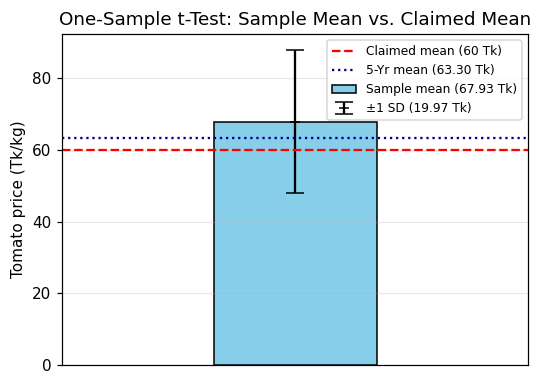

In [32]:
np.random.seed(7)
idx = np.random.permutation(len(df))[:30]          # Sample 30 random days to avoid strong serial autocorrelation
sample = df["Tomato"].values[idx]
claimed_mean = 60
alpha = 0.05

n = len(sample)
sample_mean = sample.mean()
sample_std = sample.std(ddof=1)                    # Use sample standard deviation (unbiased estimator with ddof=1)
t_manual = (sample_mean - claimed_mean) / (sample_std / np.sqrt(n))
t_stat, p_value = stats.ttest_1samp(sample, claimed_mean)
ci_1samp = stats.t.interval(0.95, df=n - 1, loc=sample_mean, scale=stats.sem(sample))

# Assumption check: Shapiro-Wilk normality test (H0: sample is normally distributed)
w_stat, p_norm = stats.shapiro(sample)
norm_msg = "no strong evidence against normality (p > 0.05)" if p_norm > 0.05 else "sample departs significantly from normality (p <= 0.05)"

# Stability / Power check: repeat the 30-day survey 2,000 times to see how often we reject H0
np.random.seed(123)
true_tomato_mean = df["Tomato"].mean()
rej_count = 0
for _ in range(2000):
    smp = df["Tomato"].values[np.random.permutation(len(df))[:30]]
    if stats.ttest_1samp(smp, claimed_mean)[1] < 0.05:
        rej_count += 1
power_1samp = rej_count / 2000 * 100

print(f"Sample size: {n}")
print(f"Sample mean: {sample_mean:.2f} Tk/kg  (True 5-year mean: {true_tomato_mean:.2f} Tk/kg)")
print(f"Sample std (ddof=1): {sample_std:.2f} Tk/kg")
print(f"t-statistic (scipy): {t_stat:.2f}  |  t-statistic (manual): {t_manual:.2f}")
print(f"Degrees of freedom: {n - 1}")
print(f"p-value: {p_value:.4f}")
print(f"95% CI for the mean: [{ci_1samp[0]:.2f}, {ci_1samp[1]:.2f}] Tk/kg")
print(f"Shapiro-Wilk p-value = {p_norm:.4f} -> {norm_msg}")
print(f"Repeated sampling check: rejected {claimed_mean} Tk/kg in {power_1samp:.1f}% of 2,000 random 30-day surveys.")

if p_value < alpha:
    print(f"Decision: Reject H0 (borderline: p = {p_value:.4f} < 0.05, but power is only {power_1samp:.1f}% at n=30).")
else:
    print(f"Decision: Fail to reject H0 (p = {p_value:.4f} >= 0.05; n=30 has only {power_1samp:.1f}% power to detect the true {true_tomato_mean:.2f} Tk/kg mean).")

# Plot Sample Mean vs. Claimed Mean with error bar (1 SD)
plt.figure(figsize=(5, 3.6))
plt.bar(1, sample_mean, width=0.35, color="skyblue", edgecolor="black", label=f"Sample mean ({sample_mean:.2f} Tk)")
plt.errorbar(1, sample_mean, yerr=sample_std, fmt="k_", capsize=6, linewidth=1.5, label=f"±1 SD ({sample_std:.2f} Tk)")
plt.axhline(claimed_mean, color="r", linestyle="--", label=f"Claimed mean ({claimed_mean} Tk)")
plt.axhline(true_tomato_mean, color="navy", linestyle=":", label=f"5-Yr mean ({true_tomato_mean:.2f} Tk)")
plt.xlim(0.5, 1.5); plt.xticks([])
plt.ylabel("Tomato price (Tk/kg)"); plt.title("One-Sample t-Test: Sample Mean vs. Claimed Mean")
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

**Interpretation (`seed=42` simulation, `seed=7` sample).** For this specific 30-day sample, $p = 0.0379 < 0.05$ and the 95% CI (`[60.47, 75.39]`) barely excludes `60`, giving a **borderline rejection of $H_0$** while passing the Shapiro-Wilk normality check ($p = 0.0665 > 0.05$). However, the 2,000-survey power check is essential context: because the true 5-year mean (`63.30 Tk/kg`) is only `3.30 Tk/kg` above `60` while the standard deviation is large (`14.52 Tk/kg` overall, `19.97 Tk/kg` in the sample), **only `19.9%` (roughly 1 in 5) of random 30-day samples reject the claim**. A 30-day sample is too small in such a volatile market to reliably detect a ~3 Tk difference.

## 8. Two-Sample *t*-Test: Winter vs. Monsoon Tomato Prices

**Question.** Are retail tomato prices significantly different between **Winter** and **Monsoon**? We draw `30` random Winter days and `30` random Monsoon days (`seed=11`) and compare:
1. **Levene's Test (`stats.levene`)** — tests equality of variances ($H_0: \sigma_{\text{Winter}}^2 = \sigma_{\text{Monsoon}}^2$).
2. **Pooled-Variance *t*-Test (`equal_var=True`)** — assumes equal population variances:
   $$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{s_p^2\left(\frac{1}{n_1}+\frac{1}{n_2}\right)}}, \qquad s_p^2 = \frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}$$
3. **Welch's *t*-Test (`equal_var=False`)** — allows unequal variances and adjusts degrees of freedom via the Welch–Satterthwaite formula.

Winter  (n=30): mean = 48.59 Tk/kg, variance = 24.65, std = 4.96
Monsoon (n=30): mean = 80.56, variance = 188.76, std = 13.74
Mean difference (Winter - Monsoon): -31.97 Tk/kg
Levene's test p-value = 0.0025 -> Variances differ significantly -> Welch's t-test is the safer choice

[Pooled t-test] s_p^2 = 106.71 | t (scipy) = -11.99, t (manual) = -11.99, df = 58, p = 2.47e-17, 95% CI = [-37.31, -26.63]
[Welch  t-test] t (scipy) = -11.99, t (manual) = -11.99, Welch df = 36.45, p = 3.30e-14, 95% CI = [-37.38, -26.56]


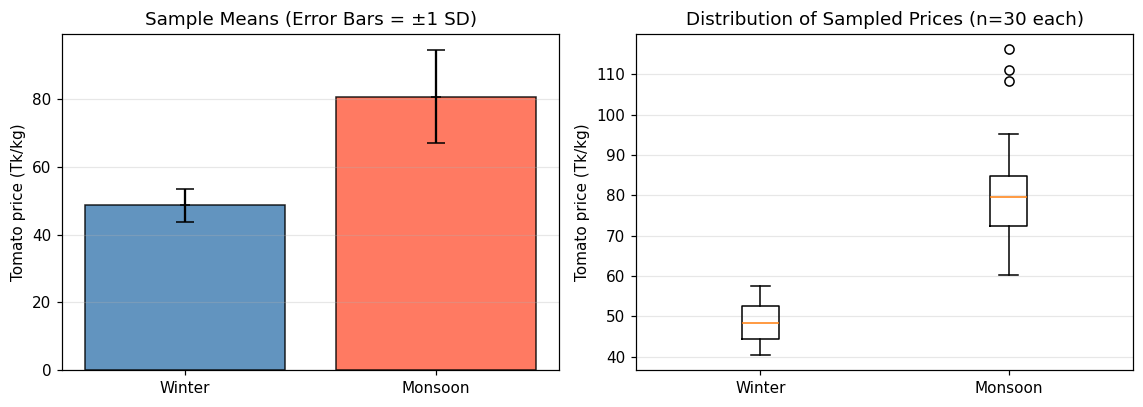

In [33]:
np.random.seed(11)
# Filter prices by season
winter  = df.loc[df["Season"] == "Winter",  "Tomato"].values
monsoon = df.loc[df["Season"] == "Monsoon", "Tomato"].values

# Draw random samples of size n=30 for each season
data1 = winter[np.random.permutation(len(winter))[:30]]
data2 = monsoon[np.random.permutation(len(monsoon))[:30]]

n1, n2 = len(data1), len(data2)
s1_sq, s2_sq = data1.var(ddof=1), data2.var(ddof=1)
mean_diff = data1.mean() - data2.mean()

# Levene's test for equality of variances (H0: variances are equal)
lev_stat, lev_p = stats.levene(data1, data2)

# 1) Standard Student's Pooled t-test (assumes equal variances)
t_pool, p_pool = stats.ttest_ind(data1, data2, equal_var=True)
sp_sq = ((n1 - 1) * s1_sq + (n2 - 1) * s2_sq) / (n1 + n2 - 2)
se_pool = np.sqrt(sp_sq * (1/n1 + 1/n2))
df_pool = n1 + n2 - 2
ci_pool = stats.t.interval(0.95, df_pool, loc=mean_diff, scale=se_pool)

# 2) Welch's t-test (unpooled, does not assume equal variances)
t_welch, p_welch = stats.ttest_ind(data1, data2, equal_var=False)
se_welch = np.sqrt(s1_sq / n1 + s2_sq / n2)
df_welch = (s1_sq/n1 + s2_sq/n2) ** 2 / ((s1_sq/n1) ** 2 / (n1 - 1) + (s2_sq/n2) ** 2 / (n2 - 1))
ci_welch = stats.t.interval(0.95, df_welch, loc=mean_diff, scale=se_welch)

print(f"Winter  (n={n1}): mean = {data1.mean():.2f} Tk/kg, variance = {s1_sq:.2f}, std = {data1.std(ddof=1):.2f}")
print(f"Monsoon (n={n2}): mean = {data2.mean():.2f}, variance = {s2_sq:.2f}, std = {data2.std(ddof=1):.2f}")
print(f"Mean difference (Winter - Monsoon): {mean_diff:.2f} Tk/kg")
print(f"Levene's test p-value = {lev_p:.4f} ->",
      "Variances look equal (pooled t-test acceptable)" if lev_p > 0.05 else "Variances differ significantly -> Welch's t-test is the safer choice")
print(f"\n[Pooled t-test] s_p^2 = {sp_sq:.2f} | t (scipy) = {t_pool:.2f}, t (manual) = {mean_diff/se_pool:.2f}, df = {df_pool}, p = {p_pool:.2e}, 95% CI = [{ci_pool[0]:.2f}, {ci_pool[1]:.2f}]")
print(f"[Welch  t-test] t (scipy) = {t_welch:.2f}, t (manual) = {mean_diff/se_welch:.2f}, Welch df = {df_welch:.2f}, p = {p_welch:.2e}, 95% CI = [{ci_welch[0]:.2f}, {ci_welch[1]:.2f}]")

# Plot the comparison
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].bar(["Winter", "Monsoon"], [data1.mean(), data2.mean()], color=["steelblue", "tomato"], alpha=0.85, edgecolor="black")
axes[0].errorbar(["Winter", "Monsoon"], [data1.mean(), data2.mean()],
                 yerr=[data1.std(ddof=1), data2.std(ddof=1)], fmt="k_", capsize=6, linewidth=1.5)
axes[0].set_ylabel("Tomato price (Tk/kg)"); axes[0].set_title("Sample Means (Error Bars = ±1 SD)")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].boxplot([data1, data2], tick_labels=["Winter", "Monsoon"])
axes[1].set_ylabel("Tomato price (Tk/kg)"); axes[1].set_title("Distribution of Sampled Prices (n=30 each)")
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Chi-Square Goodness-of-Fit: Are Price Shocks Spread Evenly Through the Year?

**Question.** If supply shocks occurred with equal probability on every day of the year, each season's expected shock count would be proportional to the number of calendar days in that season:

$$E_i = N_{\text{shocks}} \times \frac{\text{days in season } i}{\text{total days}}, \qquad \chi^2 = \sum_{i=1}^{4} \frac{(O_i - E_i)^2}{E_i}$$

- **$H_0$:** Shocks occur at an equal daily rate across all four seasons.
- **$H_1$:** Shock rates differ across seasons ($\alpha = 0.05$, $df = 4 - 1 = 3$).

,Days,Observed shocks (O),Expected shocks (E),(O - E)^2 / E
Winter,450,7,13.32,3.00
Summer,460,8,13.61,2.31
Monsoon,610,34,18.05,14.10
Autumn,305,5,9.02,1.79



Chi-square statistic (manual): 21.20 | scipy: 21.20
Degrees of freedom: 3 | Critical value (0.05): 7.81 | p-value: 0.000096
All expected counts >= 5 (test is valid): True
Reject H0: shocks concentrate significantly in Monsoon.


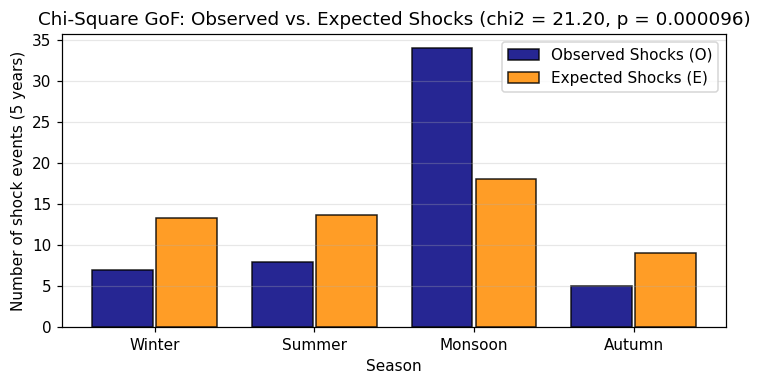

In [34]:
order = ["Winter", "Summer", "Monsoon", "Autumn"]

# Calculate observed counts of shock-start events by season
observed_chi = df.groupby("Season")["ShockStart"].sum().reindex(order).values
# Calculate total number of calendar days in each season
days_in_season = df["Season"].value_counts().reindex(order).values
# Calculate expected counts proportional to seasonal calendar length
expected_chi = observed_chi.sum() * days_in_season / days_in_season.sum()

# Compute Chi-Square statistic: sum of (O-E)^2 / E
chi_sq = np.sum((observed_chi - expected_chi) ** 2 / expected_chi)
dof = len(observed_chi) - 1
critical_chi = stats.chi2.ppf(0.95, dof) # 95% Critical value
p_chi = stats.chi2.sf(chi_sq, dof)       # Survival function (1 - CDF) to get p-value

chi_table = pd.DataFrame({
    "Days": days_in_season,
    "Observed shocks (O)": observed_chi,
    "Expected shocks (E)": expected_chi.round(2),
    "(O - E)^2 / E": ((observed_chi - expected_chi) ** 2 / expected_chi).round(2)
}, index=order)
display(chi_table)

print(f"\nChi-square statistic (manual): {chi_sq:.2f} | scipy: {stats.chisquare(observed_chi, expected_chi).statistic:.2f}")
print(f"Degrees of freedom: {dof} | Critical value (0.05): {critical_chi:.2f} | p-value: {p_chi:.6f}")
print("All expected counts >= 5 (test is valid):", bool(np.all(expected_chi >= 5)))
print("Reject H0: shocks concentrate significantly in Monsoon." if chi_sq > critical_chi else "Fail to reject H0.")

# Plot Observed vs Expected Shocks
x = np.arange(len(order))
plt.figure(figsize=(6.8, 3.6))
plt.bar(x - 0.2, observed_chi, width=0.38, label="Observed Shocks (O)", color="navy", alpha=0.85, edgecolor="black")
plt.bar(x + 0.2, expected_chi, width=0.38, label="Expected Shocks (E)", color="darkorange", alpha=0.85, edgecolor="black")
plt.xticks(x, order); plt.xlabel("Season"); plt.ylabel("Number of shock events (5 years)")
plt.title(f"Chi-Square GoF: Observed vs. Expected Shocks (chi2 = {chi_sq:.2f}, p = {p_chi:.6f})")
plt.legend(); plt.grid(True, axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 9.1 How reliable is this Chi-Square test? (2,000-History Power Simulation)
One 5-year history is a single random outcome. Below we simulate **`2,000` independent 5-year histories** (`seed=99`), verify how many satisfy the validity rule ($\forall E_i \ge 5$), and calculate the empirical **statistical power** (the percentage of valid 5-year histories where the test rejects $H_0$ at $\alpha = 0.05$).

In [35]:
np.random.seed(99)
n_hist = 2000
mon_mask = np.isin(dates.month, [6, 7, 8, 9])
p_day = np.where(mon_mask, P_MONSOON, P_OTHER)
# Generate shock matrices across 2,000 independent runs
events_mc = np.random.rand(n_hist, len(dates)) < p_day

season_arr = seasons_of(dates)
rejections, usable = 0, 0
# Loop over Monte Carlo runs and evaluate test performance
for i in range(n_hist):
    obs = np.array([events_mc[i, season_arr == s].sum() for s in order])
    if obs.sum() == 0:
        continue
    exp = obs.sum() * days_in_season / days_in_season.sum()
    # Cochran's rule check: ensure all expected cells are at least 5
    if np.all(exp >= 5):
        usable += 1
        if np.sum((obs - exp) ** 2 / exp) > critical_chi:
            rejections += 1

power_chi = rejections / usable * 100
print(f"Histories where the Chi-Square test was valid (all E_i >= 5): {usable} of {n_hist}")
print(f"Chi-square rejected H0 in {rejections} of {usable} histories (Empirical Power = {power_chi:.1f}%)")

Histories where the Chi-Square test was valid (all E_i >= 5): 2000 of 2000
Chi-square rejected H0 in 1923 of 2000 histories (Empirical Power = 96.2%)


## 10. Monte Carlo Experiment: Household Budget Risk & 3D Seasonal Trajectory

### 10.1 Monthly Basket Distribution & True 95% Range (`[2.5, 97.5]` Percentiles)
A household buys a weekly basket of **`1 kg tomato + 2 kg potato + 1 kg onion + 1 kg brinjal`**, shopping `4` times per month (`days [0, 7, 14, 21]` in January vs. `days [181, 188, 195, 202]` in July). We simulate **`2,000` independent years** (`seed=2024`) and compute:
1. The true **95% range (`2.5th` to `97.5th` percentiles)** and **90% range (`5th` to `95th` percentiles)** of monthly spending.
2. A **Budget Sweep from `1,000 Tk` to `1,500 Tk`** showing how the exceedance probability $P(\text{Cost} > B)$ and coverage probability $P(\text{Cost} \le B)$ change across budget thresholds, alongside the exact **80th, 90th, 95th, and 97.5th percentile July budgets**.

In [36]:
np.random.seed(2024)
n_runs = 2000
year_dates = pd.date_range("2023-01-01", periods=365)
# Simulate 2,000 years to estimate distributions and probabilities
mc_prices, mc_events, _ = simulate(n_runs, year_dates)

# Construct daily cost of the household vegetable basket
basket = (1 * mc_prices["Tomato"] + 2 * mc_prices["Potato"]
          + 1 * mc_prices["Onion"] + 1 * mc_prices["Brinjal"])

jan_days  = [0, 7, 14, 21]          # Shopping schedule for January
jul_days  = [181, 188, 195, 202]    # Shopping schedule for July
jan_cost = basket[:, jan_days].sum(axis=1)
jul_cost = basket[:, jul_days].sum(axis=1)

budget = 1000
for label, cost in [("January (winter)", jan_cost), ("July (monsoon)  ", jul_cost)]:
    lo95, hi95 = np.percentile(cost, [2.5, 97.5]) # Estimate standard 95% interval boundaries
    lo90, hi90 = np.percentile(cost, [5.0, 95.0]) # Estimate standard 90% interval boundaries
    print(f"{label}: mean = {cost.mean():.0f} Tk, std = {cost.std():.0f} Tk | "
          f"95% range [2.5, 97.5] = [{lo95:.0f}, {hi95:.0f}] Tk | "
          f"90% range [5, 95] = [{lo90:.0f}, {hi90:.0f}] Tk | P(cost > {budget}) = {np.mean(cost > budget) * 100:.1f}%")

# Budget sweep calculations
budgets = [1000, 1100, 1200, 1250, 1300, 1350, 1400, 1450, 1500]
sweep_df = pd.DataFrame({
    "Budget Threshold (Tk)": budgets,
    "Jan Overrun P(Cost > B) (%)": [np.mean(jan_cost > b) * 100 for b in budgets],
    "Jul Overrun P(Cost > B) (%)": [np.mean(jul_cost > b) * 100 for b in budgets],
    "Jul Coverage P(Cost <= B) (%)": [np.mean(jul_cost <= b) * 100 for b in budgets],
})
print("\n--- Household Monthly Budget Sweep (1,000 Tk to 1,500 Tk) ---")
display(sweep_df.round(1))

cov_1250 = np.mean(jul_cost <= 1250) * 100
cov_1300 = np.mean(jul_cost <= 1300) * 100
jul_p80, jul_p90, jul_p95, jul_p975 = np.percentile(jul_cost, [80, 90, 95, 97.5])
print(f"\nJuly Budget Quantiles -> 80th pct: {jul_p80:.0f} Tk | 90th pct: {jul_p90:.0f} Tk | 95th pct: {jul_p95:.0f} Tk | 97.5th pct: {jul_p975:.0f} Tk")
print(f"July Coverage at 1,250–1,300 Tk -> {cov_1250:.1f}% to {cov_1300:.1f}% (approx {cov_1250:.0f}%–{cov_1300:.0f}%)")

shocks_per_year = mc_events.sum(axis=1)
peak_tomato = mc_prices["Tomato"].max(axis=1)
print(f"Expected shock events per year: {shocks_per_year.mean():.1f} (std {shocks_per_year.std():.1f})")
print(f"Average yearly peak tomato price: {peak_tomato.mean():.0f} Tk/kg | 95th percentile peak: {np.percentile(peak_tomato, 95):.0f} Tk/kg")

January (winter): mean = 937 Tk, std = 35 Tk | 95% range [2.5, 97.5] = [893, 1027] Tk | 90% range [5, 95] = [899, 1008] Tk | P(cost > 1000) = 6.8%
July (monsoon)  : mean = 1229 Tk, std = 84 Tk | 95% range [2.5, 97.5] = [1105, 1429] Tk | 90% range [5, 95] = [1118, 1383] Tk | P(cost > 1000) = 100.0%

--- Household Monthly Budget Sweep (1,000 Tk to 1,500 Tk) ---


,Budget Threshold (Tk),Jan Overrun P(Cost > B) (%),Jul Overrun P(Cost > B) (%),Jul Coverage P(Cost <= B) (%)
0,1000,6.8,100.0,0.0
1,1100,0.2,98.6,1.5
2,1200,0.0,58.1,41.9
3,1250,0.0,36.2,63.8
4,1300,0.0,18.5,81.5
5,1350,0.0,8.6,91.4
6,1400,0.0,3.8,96.2
7,1450,0.0,1.6,98.4
8,1500,0.0,0.6,99.4



July Budget Quantiles -> 80th pct: 1295 Tk | 90th pct: 1341 Tk | 95th pct: 1383 Tk | 97.5th pct: 1429 Tk
July Coverage at 1,250–1,300 Tk -> 63.8% to 81.5% (approx 64%–82%)
Expected shock events per year: 12.2 (std 3.4)
Average yearly peak tomato price: 122 Tk/kg | 95th percentile peak: 146 Tk/kg


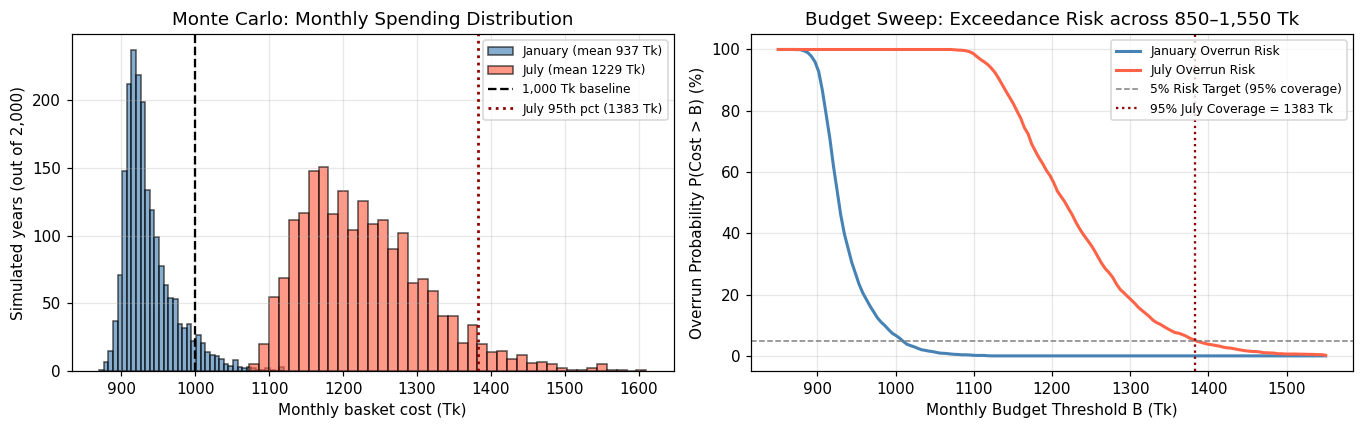

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
axes[0].hist(jan_cost, bins=40, alpha=0.65, color="steelblue", edgecolor="black", label=f"January (mean {jan_cost.mean():.0f} Tk)")
axes[0].hist(jul_cost, bins=40, alpha=0.65, color="tomato", edgecolor="black", label=f"July (mean {jul_cost.mean():.0f} Tk)")
axes[0].axvline(1000, color="black", linestyle="--", label="1,000 Tk baseline")
axes[0].axvline(jul_p95, color="darkred", linestyle=":", linewidth=1.8, label=f"July 95th pct ({jul_p95:.0f} Tk)")
axes[0].set_xlabel("Monthly basket cost (Tk)"); axes[0].set_ylabel("Simulated years (out of 2,000)")
axes[0].set_title("Monte Carlo: Monthly Spending Distribution")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

b_grid = np.linspace(850, 1550, 150)
axes[1].plot(b_grid, [np.mean(jan_cost > b) * 100 for b in b_grid], color="steelblue", linewidth=2, label="January Overrun Risk")
axes[1].plot(b_grid, [np.mean(jul_cost > b) * 100 for b in b_grid], color="tomato", linewidth=2, label="July Overrun Risk")
axes[1].axhline(5.0, color="gray", linestyle="--", linewidth=1, label="5% Risk Target (95% coverage)")
axes[1].axvline(jul_p95, color="darkred", linestyle=":", linewidth=1.5, label=f"95% July Coverage = {jul_p95:.0f} Tk")
axes[1].set_xlabel("Monthly Budget Threshold B (Tk)"); axes[1].set_ylabel("Overrun Probability P(Cost > B) (%)")
axes[1].set_title("Budget Sweep: Exceedance Risk across 850–1,550 Tk")
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()